# 03 – pandas with the ESOL solubility dataset

**Goal:** load, inspect, filter, extend, summarize and plot a real chemistry dataset with pandas. **Time:** about 3 hours, including exercises.

1. Loading a CSV
2. Inspecting a DataFrame
3. Selecting columns and rows
4. Sorting
5. Adding columns, including RDKit properties
6. Missing and invalid values
7. Grouping and summarizing
8. Plotting with matplotlib

There's one exercise per section, plus a short final exercise. The optional notebook `03b_bonus_esol.ipynb` re-implements Delaney's solubility equation.

Before saving, check that the notebook still works after **Restart Kernel → Run All**.

## The dataset

**ESOL** contains measured aqueous solubilities for 1,128 organic compounds. The target value is **logS**, the log₁₀ of the solubility in mol/L.

- **Source:** the processed CSV from the DeepChem repository, `datasets/delaney-processed.csv`
  https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv
  It's saved in `data/delaney-processed.csv`. It was downloaded with:
  `curl -L -o data/delaney-processed.csv <URL above>`
- **Citation:** J. S. Delaney, "ESOL: Estimating Aqueous Solubility Directly from Molecular Structure", *J. Chem. Inf. Comput. Sci.* **2004**, *44*, 1000–1005. DOI: [10.1021/ci034243x](https://doi.org/10.1021/ci034243x)
- The same data is part of the MoleculeNet benchmark: Z. Wu et al., *Chem. Sci.* **2018**, *9*, 513–530.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, rdMolDescriptors

- **pandas** is the table library; `pd` is the standard short name.
- **NumPy** is the array library that pandas is built on. Here it's only needed for `np.nan`, the "missing number" value.
- **matplotlib** draws the plots.

## 1. Loading a CSV

A **DataFrame** is a table: named columns, each with one data type, and rows identified by an **index**. A single column is a **Series**.

| | pandas | R |
|---|---|---|
| read a CSV | `pd.read_csv("file.csv")` | `read.csv()` / `readr::read_csv()` |
| table type | `DataFrame` | `data.frame` / tibble |
| one column | `Series` | a vector |

In [2]:
df = pd.read_csv("data/delaney-processed.csv")
df.head()

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


The original column names are long. `rename` takes a dict that maps old names to new names and returns a **new** DataFrame, so you have to assign the result. In dplyr the order is reversed: `rename(new = old)`.

In [3]:
df = df.rename(columns={
    "Compound ID": "name",
    "ESOL predicted log solubility in mols per litre": "logS_esol",
    "Minimum Degree": "min_degree",
    "Molecular Weight": "mw",
    "Number of H-Bond Donors": "hbd",
    "Number of Rings": "n_rings",
    "Number of Rotatable Bonds": "n_rot_bonds",
    "Polar Surface Area": "tpsa",
    "measured log solubility in mols per litre": "logS",
})

df.columns

Index(['name', 'logS_esol', 'min_degree', 'mw', 'hbd', 'n_rings',
       'n_rot_bonds', 'tpsa', 'logS', 'smiles'],
      dtype='str')

- `logS` is the **measured** solubility.
- `logS_esol` is the value predicted by Delaney's equation.
- The other numeric columns were precomputed by DeepChem.

### Exercise 1

Use the `nrows` argument of `pd.read_csv` to read **only the first 10 rows** into `df_small`, and check its length with `len()`. What would `nrows` be useful for with a file of several GB?

In [4]:
# Exercise 1: your code here
df_small = pd.read_csv("data/delaney-processed.csv", nrows=10)
len(df_small)

10

nrows is useful for a large file with several GBs to check only few entries without having to get all the data.
-> Shorter time to load
-> Less memory used.
-> Testing of code with only small sample possible.

## 2. Inspecting a DataFrame

| pandas | R | Gives |
|---|---|---|
| `df.shape` | `dim(df)` | (rows, columns) |
| `df.head(n)` | `head()` | first n rows |
| `df.info()` | `str(df)` | columns, types, non-missing counts |
| `df.describe()` | `summary(df)` | count, mean, std, min, quartiles, max |
| `df["col"].value_counts()` | `table(df$col)` | how often each value occurs |

`shape` and `columns` are **attributes**, written without parentheses. `head()`, `info()` and `describe()` are **methods**, so they need `()`.

In [5]:
print(df.shape)
df.info()

(1128, 10)
<class 'pandas.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name         1128 non-null   str    
 1   logS_esol    1128 non-null   float64
 2   min_degree   1128 non-null   int64  
 3   mw           1128 non-null   float64
 4   hbd          1128 non-null   int64  
 5   n_rings      1128 non-null   int64  
 6   n_rot_bonds  1128 non-null   int64  
 7   tpsa         1128 non-null   float64
 8   logS         1128 non-null   float64
 9   smiles       1128 non-null   str    
dtypes: float64(4), int64(4), str(2)
memory usage: 88.3 KB


- `float64` is a decimal number, and `int64` is an integer.
- `str` is text. pandas 3 gives text columns their own string type; older versions show `object`.
- `Non-Null Count` shows that nothing is missing.

In [6]:
df.describe()

,logS_esol,min_degree,mw,hbd,n_rings,n_rot_bonds,tpsa,logS
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-2.988192,1.058511,203.937074,0.701241,1.390957,2.177305,34.872881,-3.050102
std,1.683220,0.238560,102.738077,1.089727,1.318286,2.640974,35.383593,2.096441
min,-9.702000,0.000000,16.043000,0.000000,0.000000,0.000000,0.000000,-11.600000
25%,-3.948250,1.000000,121.183000,0.000000,0.000000,0.000000,0.000000,-4.317500
50%,-2.870000,1.000000,182.179000,0.000000,1.000000,1.000000,26.300000,-2.860000
75%,-1.843750,1.000000,270.372000,1.000000,2.000000,3.000000,55.440000,-1.600000
max,1.091000,2.000000,780.949000,11.000000,8.000000,23.000000,268.680000,1.580000


`describe()` summarizes only numeric columns. logS runs from −11.6 to +1.58, which spans more than 13 orders of magnitude in mol/L.

### Exercise 2

1. What is the median logS? Look at the 50% row of `describe()`, or use `df["logS"].median()`.
2. Roughly how many mg/L is the median for a compound of MW 200? Calculate it in a cell: mol/L × g/mol gives g/L.

In [7]:
# Exercise 2: your code here
median_logs = df.describe().loc["50%", "logS"]
print(f"Median logS: {median_logs:.2f}")

solubility_mol_L = 10 ** median_logs
mw = 200
solubility_mg_L = solubility_mol_L * mw * 1000  # Convert to mg/L

print(f"Solubility: {solubility_mg_L:.0f} mg/L")


Median logS: -2.86
Solubility: 276 mg/L


## 3. Selecting columns and rows

- **Columns:** `df["logS"]` gives one column as a Series. `df[["name", "logS"]]` gives several columns as a DataFrame; the inner brackets are a list. This is dplyr's `select()`.
- **Rows by position:** `df.iloc[...]` is 0-based, and the end of a slice is **excluded**, as with lists.
- **Rows by label:** `df.loc[...]` uses index labels, and the end of a slice is **included**.

Both take `[rows, columns]`.

In [8]:
print(len(df.iloc[0:5]))   # positions 0-4: 5 rows
print(len(df.loc[0:5]))    # labels 0-5 inclusive: 6 rows

by_name = df.set_index("name")            # compound names become the row labels
by_name.loc["Coronene", ["logS", "mw"]]

5
6


logS     -9.332
mw      300.360
Name: Coronene, dtype: float64

### Boolean filtering

A comparison on a column gives a Series of `True`/`False`, called a **mask**. `df[mask]` keeps the rows where the mask is `True`. This is dplyr's `filter()`.

- Combine conditions with `&`, `|` and `~`, **not** `and`, `or` and `not`.
- Put each condition in parentheses, because `&` binds more tightly than `<`.
- To change values in matching rows, use `df.loc[mask, "col"] = value` in one step. The chained form `df[mask]["col"] = value` has no effect in pandas 3.

In [9]:
mask = (df["logS"] > -1) & (df["n_rings"] >= 1)
print(mask.sum())                          # True counts as 1

df.loc[mask, ["name", "logS", "n_rings"]].head()

76


,name,logS,n_rings
0,Amigdalin,-0.770,3
10,2-pyrrolidone,1.070,1
55,2-Methylphenol,-0.620,1
63,p-Aminophenol,-0.800,1
67,Pyrazinamide,-0.667,1


### Exercise 3

How many compounds have **logS < −6** and **TPSA > 50 Å²**? Show their names, logS and TPSA. Then draw them with `Draw.MolsToGridImage`, with their names as legends. What do they have in common structurally?

21


,name,logS,tpsa
86,Flucythrinate,-6.876,68.55
127,Cyfluthrin,-7.337,59.32
167,3-Octanoyloxymethylphenytoin,-6.523,75.71
169,Ethalfluralin,-6.124,89.52
175,3-Heptanoyloxymethylphenytoin,-6.301,75.71
260,Dialifor,-6.340,55.84
262,TEFLUBENZURON,-7.280,58.20
272,Deltamethrin,-8.402,59.32
303,Isopropalin,-6.490,89.52
344,Lovastatin,-6.005,72.83


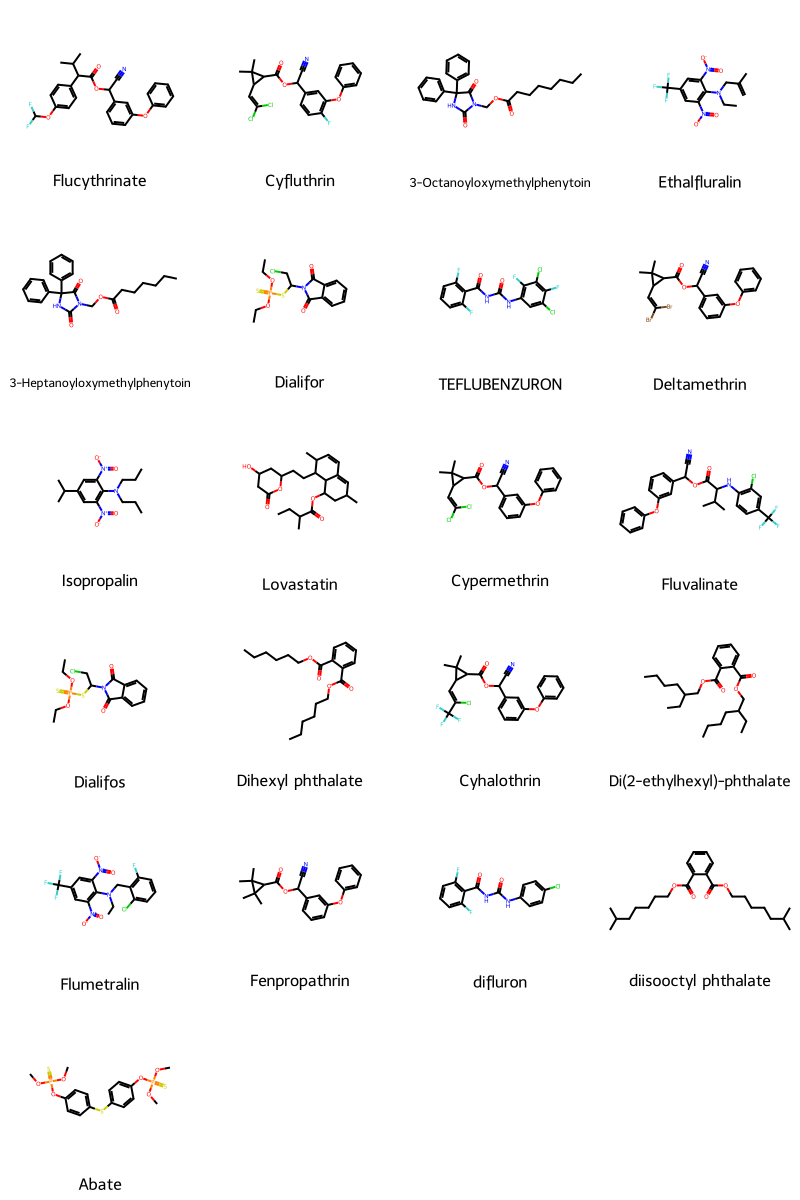

In [10]:
# Exercise 3: your code here
mask = (df["logS"] < -6) & (df["tpsa"] > 50)
print(mask.sum())  # True counts as 1. 

display(df.loc[mask, ["name", "logS", "tpsa"]])

Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in df.loc[mask, "smiles"]], molsPerRow=4, legends=list(df.loc[mask, "name"]),subImgSize=(200, 200))  

logS < -6 means practically insoluble in water.

| logS | Solubility | For MW 300 | In lab terms |
|---:|---|---|---|
| 0 | 1 mol/L | 300 g/L | very soluble, like a sugar |
| −2 | 10 mmol/L | 3 g/L | soluble |
| −4 | 100 µmol/L | 30 mg/L | poorly soluble |
| −6 | 1 µmol/L | 0.3 mg/L | practically insoluble |
| −8 | 10 nmol/L | 3 µg/L | barely detectable in water |

tpsa > 50 means that the molecule has several polar groups. (tpsa = surface area of N and O and their H-atoms. i.e. measure of how many polar, hydrogen-bonding groups the molecule has)

| TPSA (Å²) | Roughly corresponds to |
|---:|---|
| 0 | a hydrocarbon (benzene, hexane) |
| ~20 | one OH (ethanol) |
| ~40–60 | two polar groups, e.g. an ester plus an amide |
| ~70 | a nitro group plus an amine (4-nitroaniline) |
| ~110 | many OH groups (glucose) |


These molecules have aromatic groups (and some aliphatic chains) as well as polar groups (esters, nitro compounds, urea groups) that are often in a compact region. The polar groups are mostly H-bond acceptors. 
Apparently most of these structures are agrochemicals, so they're designed to be lipophilic. 
Many molecules also have halogens, that add hydrophobic bulk with very little hydrogen bonding.

Conclusion: TPSA only measures the polar part but it ignores how large the hydrophobic part is. And the actual solubility depends on the balance between those.

## 4. Sorting

`df.sort_values("col")` sorts ascending; pass `ascending=False` for descending. This is dplyr's `arrange()`.

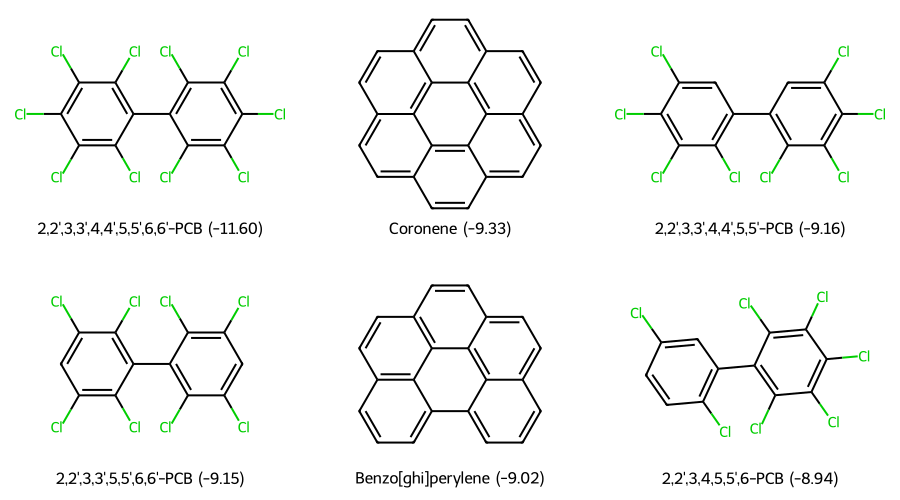

In [11]:
least_soluble = df.sort_values("logS").head(6)

Draw.MolsToGridImage(
    [Chem.MolFromSmiles(smi) for smi in least_soluble["smiles"]],
    legends=[f"{name} ({logs:.2f})" for name, logs in zip(least_soluble["name"], least_soluble["logS"])],
    molsPerRow=3,
    subImgSize=(300, 250),
)

Polychlorinated biphenyls and large polycyclic aromatics: flat, hydrophobic, and with strong crystal packing.

- **Several columns:** `sort_values(["n_rings", "logS"], ascending=[False, True])`.
- **Shortcuts:** `df.nlargest(n, "col")` and `df.nsmallest(n, "col")`.
- **Index labels move with the rows when you sort.** `reset_index(drop=True)` renumbers them.

### Exercise 4

Show the 10 compounds with the **largest TPSA**, together with their logS. Are polar compounds automatically soluble?

In [12]:
# Exercise 4: your code here
largest_tpsa = df.sort_values("tpsa", ascending=False).head(10)

largest_tpsa[["name", "tpsa", "logS"]]

,name,tpsa,logS
298,Raffinose,268.68,-0.410
555,"Digoxin (L1=41,8mg/mL, L2=68,2mg/mL, Z=40,1mg/mL)",203.06,-4.081
0,Amigdalin,202.32,-0.770
733,alloxantin,191.00,-1.990
1025,Sucrose,189.53,0.790
441,Lactose,189.53,-0.244
1050,Monotropitoside,184.60,-0.742
640,Digitoxin,182.83,-5.293
588,Riboflavin,161.56,-3.685
219,"Etoposide (148-167,25mg/ml)",160.83,-3.571


Polar molecules are not automatically soluble in water. For example, digoxin: It is the second most polar but it's significantly less soluble in water than the entries before and after. This is similar to the previous exercise because solely the number of polar groups does not tell us if the molecule is water soluble. Digoxin has a hydrophobic steroid aglycone which makes it very insoluble.
Sugars however, are better soluble because they do not have an additional big aliphatic ring system. Riboflavin looks really planar as well, so they might pack well in a crystal with pi-stacking and intermolecular H-bonds.

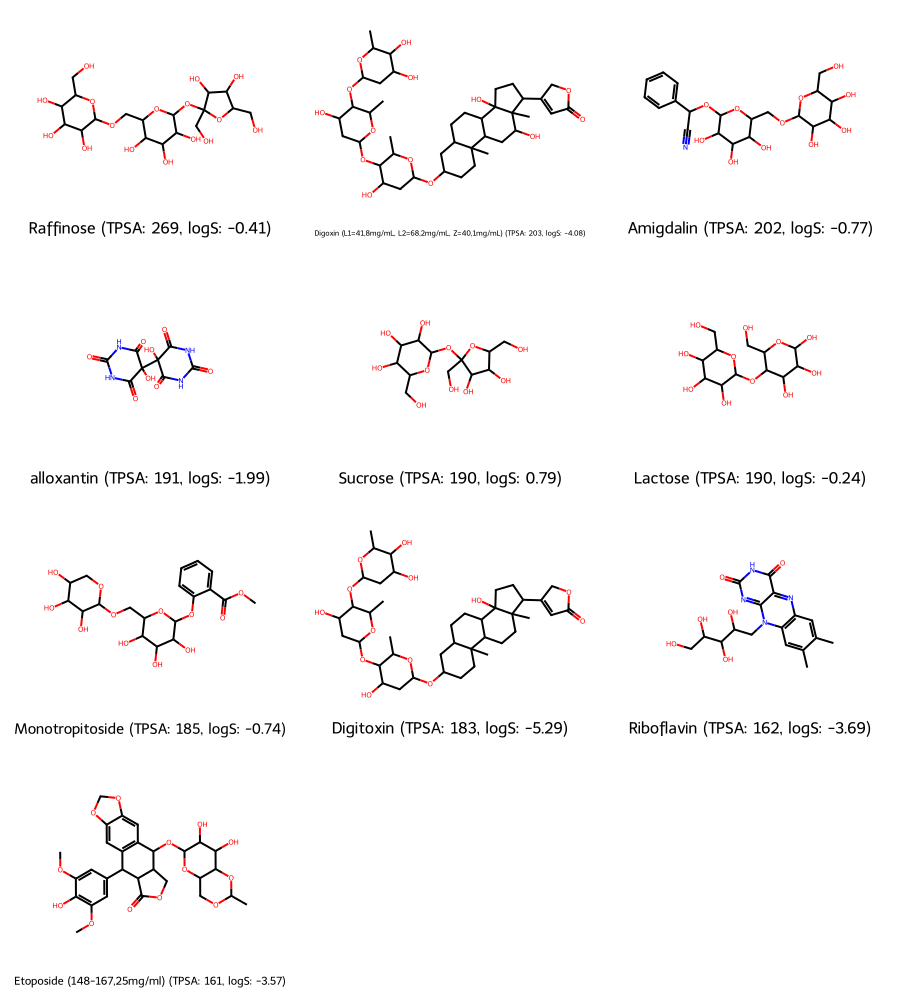

In [13]:
Draw.MolsToGridImage(
    [Chem.MolFromSmiles(smi) for smi in largest_tpsa["smiles"]],
    legends=[f"{name} (TPSA: {tpsa:.0f}, logS: {logS:.2f})" for name, tpsa, logS in zip(largest_tpsa["name"], largest_tpsa["tpsa"], largest_tpsa["logS"])],
    molsPerRow=3,
    subImgSize=(300, 250)
)

## 5. Adding columns

Arithmetic on columns runs element by element over all rows, like R vectors and without a loop. Assigning to a new name creates the column. This is dplyr's `mutate()`.

In [14]:
df["sol_mol_L"] = 10 ** df["logS"]
df[["name", "logS", "sol_mol_L"]].head(3)

,name,logS,sol_mol_L
0,Amigdalin,-0.77,0.169824
1,Fenfuram,-3.30,0.000501
2,citral,-2.06,0.008710


RDKit functions work on one molecule at a time. `series.apply(f)` calls `f` on every element. Pass the function **without parentheses**, as with `key=` in `sorted()`. A column can hold RDKit `Mol` objects, so each SMILES only needs to be parsed once.

In [15]:
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
df["mw_rdkit"] = df["mol"].apply(Descriptors.MolWt)
df["n_arom_rings"] = df["mol"].apply(rdMolDescriptors.CalcNumAromaticRings)

print((df["mw_rdkit"] - df["mw"]).abs().max())    # sanity check against the precomputed MW
df[["name", "mw_rdkit", "n_rings", "n_arom_rings"]].head()

5.684341886080802e-14


,name,mw_rdkit,n_rings,n_arom_rings
0,Amigdalin,457.432,3,1
1,Fenfuram,201.225,2,2
2,citral,152.237,0,0
3,Picene,278.354,5,5
4,Thiophene,84.143,1,1


- **The MW columns agree** to within about 10⁻¹⁴, which is floating-point noise. DeepChem used RDKit too.
- **Use `lambda` for multi-step functions**, e.g. `df["mol"].apply(lambda mol: mol.GetNumHeavyAtoms())`.
- **`apply` is a Python loop.** That's fine for a thousand molecules but slow for millions of rows. Prefer plain column arithmetic whenever you don't need RDKit.

### Exercise 5

Add a column `logp` with the Crippen logP (`Descriptors.MolLogP`). Show `name`, `logp` and `logS` for the first 5 rows. You'll need `logp` again in section 8.

In [16]:
# Exercise 5: your code here
df["logp"] = df["mol"].apply(Descriptors.MolLogP).round(2)

df[["name", "logp", "logS"]].head()




,name,logp,logS
0,Amigdalin,-3.11,-0.77
1,Fenfuram,2.84,-3.30
2,citral,2.88,-2.06
3,Picene,6.30,-7.87
4,Thiophene,1.75,-1.33


P is the partition coefficient of a compound between 1-octanol and water. You shake the compound with both liquids, let the phases separate, and measure the concentration in each:

P = [compound]_octanol / [compound]_water  logP = log₁₀ P

logP = 0: equal concentrations in both phases.
logP = 2: 100 times more in octanol. The compound is lipophilic.
logP = −2: 100 times more in water. The compound is hydrophilic.


## 6. Missing and invalid values

pandas marks missing values as `NaN` or `None`. R uses `NA` for both.

| pandas | R |
|---|---|
| `df.isna()` / `df.notna()` | `is.na()` / `!is.na()` |
| `df.dropna(subset=["col"])` | `tidyr::drop_na(col)` |
| `df.fillna(value)` | `tidyr::replace_na()` |

In [17]:
df.isna().sum().sum()    # total number of missing values in the whole table

np.int64(0)

ESOL has no missing values, but it has a hidden problem: some SMILES end with whitespace. The `.str` accessor applies string methods to a whole column, like R's `stringr`:

In [18]:
has_whitespace = df["smiles"] != df["smiles"].str.strip()
print(has_whitespace.sum())

df.loc[has_whitespace, "smiles"].head(3).tolist()

212


['OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O ',
 'c2ccc1scnc1c2 ',
 'COc5cc4OCC3Oc2c1CC(Oc1ccc2C(=O)C3c4cc5OC)C(C)=C ']

RDKit treats anything after a space as a molecule name, so these SMILES still parse. But a string comparison, for example a check for duplicates or a merge with another table, would treat `"CCO "` and `"CCO"` as different molecules. `str.strip()` removes the whitespace:

In [19]:
df["smiles"] = df["smiles"].str.strip()
(df["smiles"] != df["smiles"].str.strip()).sum()

np.int64(0)

### A messy example

Here's a copy of five rows with two problems put in on purpose: one missing measurement and one invalid SMILES. `.copy()` makes an independent DataFrame, as with lists in notebook 02.

In [20]:
messy = df.loc[0:4, ["name", "smiles", "logS"]].copy()
messy.loc[1, "logS"] = np.nan        # missing measurement
messy.loc[3, "smiles"] = "C1CC"      # unclosed ring
messy["mol"] = messy["smiles"].apply(Chem.MolFromSmiles)

messy.isna()

[11:57:08] SMILES Parse Error: unclosed ring for input: 'C1CC'


,name,smiles,logS,mol
0,False,False,False,False
1,False,False,True,False
2,False,False,False,False
3,False,False,False,True
4,False,False,False,False


- The invalid SMILES gave `None` in `mol`, and `isna()` detects it.
- Filter invalid molecules **before** you `apply` an RDKit function, because `Descriptors.MolWt(None)` raises an error.
- Use `fillna()` for defaults like a label, never to invent measurements.

### Exercise 6

Clean `messy` so it keeps only rows with **both** a measured logS **and** a valid molecule. How many rows remain? Check that the original `messy` is unchanged.

In [21]:
# Exercise 6: your code here
# Row 1: logS is missing
# Row 3: Smiles invalid, so mol is None

step1 = messy.dropna(subset=["logS"])
clean = step1[step1["mol"].notna()]

print(f"Length of clean dataset: {len(clean)}, Length of messy dataset: {len(messy)}")

Length of clean dataset: 3, Length of messy dataset: 5


## 7. Grouping and summarizing

`groupby` splits the rows into groups, summarizes each group, and combines the results. This is dplyr's `group_by() %>% summarise()`. **Named aggregations** set the output column names: `new_name=("column", "function")`.

In [22]:
summary = df.groupby("n_arom_rings").agg(
    mean_logS=("logS", "mean"),
    n=("logS", "count"),
)

summary

,mean_logS,n
n_arom_rings,,
0,-2.286009,466
1,-2.748441,372
2,-4.366622,225
3,-4.799690,42
4,-7.048125,16
5,-7.523600,5
6,-9.018000,1
7,-9.332000,1


More aromatic rings means lower solubility. **Always look at the count:** the groups with 6 and 7 rings each contain a single compound, so their means mean little. The grouping column becomes the index of the result; `.reset_index()` turns it back into a column.

### Exercise 7

Group by `hbd` (number of H-bond donors), and calculate the mean logS, the mean TPSA and the count per group. Is there a trend? Which groups are too small to trust?

In [23]:
# Exercise 7: your code here
grouped = df.groupby("hbd").agg(
    mean_logS=("logS", "mean"),
    mean_tpsa=("tpsa", "mean"),
    n=("logS", "count"),
)

grouped

,mean_logS,mean_tpsa,n
hbd,,,
0,-3.465964,17.775843,635
1,-2.528254,40.128339,307
2,-2.608328,70.305036,137
3,-3.047455,102.088182,22
4,-1.962818,112.985455,11
5,-1.921833,136.020000,6
6,-0.885500,157.133333,6
7,-0.770000,202.320000,1
8,0.273000,189.530000,2


The more H-bond donors, the higher the logS and TPSA, however, it's not monotonic. There are rises and dips, e.g. hbd = 8. But there are only few examples for hbd = 4 - 11, so the group is too small to trust. The biggest dip is from hbd = 2 -> 3. The groups have many molecules. It might come from the steroid-glycoside effect. From previous exercises, I remember the molecules with a steroid core but many OH groups. They were basically insoluble but their TPSA was high due to the large amount of OH groups. The TPSA rises with hbd, because the hbd are usually NH or OH groups and they add to the TPSA. The biggest rise is from hbd = 0 -> 1 because logS is increased by almost 1. If there are no hbds in a molecule, they are poorly soluble due to the inability to donate hbd to water. The aromatics (flat) pack well in a crystal, or there are halogenated aromatics.

## 8. Plotting with matplotlib

The same pattern as the caption figure in notebook 01:

1. `fig, ax = plt.subplots()`
2. draw on `ax`
3. label the axes, with units
4. `plt.show()`

It corresponds to ggplot2's layers, written as separate commands.

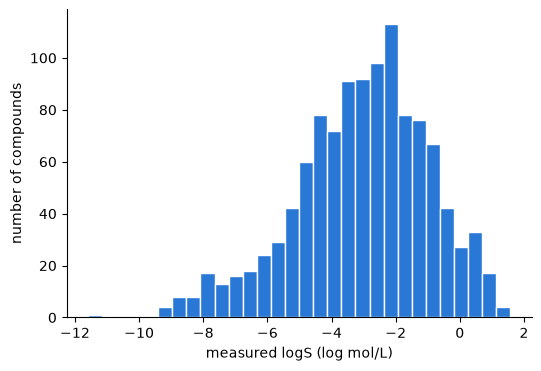

In [24]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df["logS"], bins=30, color="#2a78d6", edgecolor="white")
ax.set_xlabel("measured logS (log mol/L)")
ax.set_ylabel("number of compounds")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

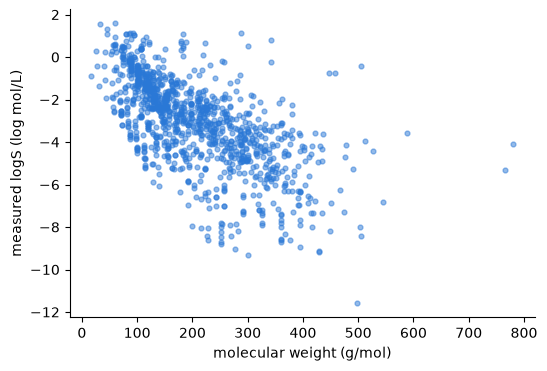

In [25]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["mw_rdkit"], df["logS"], s=12, alpha=0.5, color="#2a78d6")
ax.set_xlabel("molecular weight (g/mol)")
ax.set_ylabel("measured logS (log mol/L)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- **Plot settings:**
  - `edgecolor="white"` separates the histogram bars.
  - `alpha` makes points transparent, so dense regions look darker.
  - `s` sets the marker size.
  - Hiding the top and right spines removes frame lines that carry no information.
- **The trend is downward but noisy:** around MW 300, logS ranges from about −9 to 0. MW alone is a weak predictor.
- **pandas shortcuts** such as `df.plot.scatter(x=..., y=...)` are handy for a quick look.

### Exercise 8

Make a scatter plot of `logp` (from Exercise 5) against `logS`. Does logP track solubility more closely than MW? Quantify it with `df["logS"].corr(df["logp"])`, the Pearson correlation coefficient, and compare it with the coefficient for `mw_rdkit`.

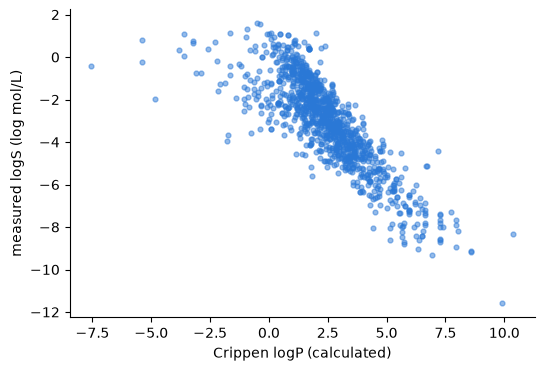

Pearson correlation between logS and logP: -0.83
Pearson correlation between logS and molecular weight: -0.64
R-squared between logS and logP: 0.69
R-squared between logS and molecular weight: 0.41


In [26]:
# Exercise 8: your code here
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["logp"], df["logS"], s=12, alpha=0.5, color="#2a78d6")
ax.set_xlabel("Crippen logP (calculated)")
ax.set_ylabel("measured logS (log mol/L)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

pearson_logp = df["logS"].corr(df["logp"])
pearson_mw = df["logS"].corr(df["mw_rdkit"])

print(f"Pearson correlation between logS and logP: {pearson_logp:.2f}")
print(f"Pearson correlation between logS and molecular weight: {pearson_mw:.2f}")

# Quantitative r2
print(f"R-squared between logS and logP: {pearson_logp**2:.2f}")
print(f"R-squared between logS and molecular weight: {pearson_mw**2:.2f}")

The **Pearson correlation coefficient** *r* measures how closely two variables follow a straight-line relationship. It's a single number between −1 and +1:

| *r* | Meaning |
|---:|---|
| +1 | perfect line, rising: when *x* goes up, *y* goes up |
| 0 | no linear relationship |
| −1 | perfect line, falling: when *x* goes up, *y* goes down |
| ±0.3 | weak trend, lots of scatter |
| ±0.7 | clear trend, moderate scatter |
| ±0.9 | tight trend, little scatter |

The scatter plot shows a downward trend, i.e. with higher logp the molecule is also less soluble. It is less noisy than the plot logS against the molecular weight. 

The Pearson correlation coefficient supports this because both are negative: Going down with bigger x. The absolute value of the Pearson correlation coefficient between logS and logP is greater.

Quantitative comparison with r2: For logS and logP, the linear trend explaisn about 70% of the variance in logS. The MW explains only about 40%.

## Final exercise

Start from the raw file, so the result doesn't depend on earlier cells.

1. **Load and clean:** read the CSV into a new DataFrame `esol`, rename the columns (reuse the dict from section 1), strip whitespace from the SMILES, parse them into a `mol` column, and drop rows where parsing failed. Print the number of rows.
2. **Add one RDKit column:** `logp` (Crippen logP).
3. **Summarize and plot:**
   - Group by `n_rings` and report the mean logS, the mean logP and the count.
   - Make one plot: mean logP against mean logS for the groups, or logP against logS for all compounds.
   - In one sentence: what do you conclude?

In [27]:
# Final exercise, step 1: load and clean
esol = pd.read_csv("data/delaney-processed.csv")
esol = esol.rename(columns={
    "Compound ID": "name",
    "ESOL predicted log solubility in mols per litre": "logS_esol",
    "Minimum Degree": "min_degree",
    "Molecular Weight": "mw",
    "Number of H-Bond Donors": "hbd",
    "Number of Rings": "n_rings",
    "Number of Rotatable Bonds": "n_rot_bonds",
    "Polar Surface Area": "tpsa",
    "measured log solubility in mols per litre": "logS",
})
esol["smiles"] = esol["smiles"].str.strip()
esol["mol"] = esol["smiles"].apply(Chem.MolFromSmiles)
esol = esol[esol["mol"].notna()]

print(f"Length of cleaned dataset: {len(esol)}")

Length of cleaned dataset: 1128


In [28]:
# Final exercise, step 2: add logp
esol["logp"] = esol["mol"].apply(Descriptors.MolLogP)

,mean_logS,mean_logP,n
n_rings,,,
0,-1.91,1.92,317
1,-2.55,2.06,386
2,-3.96,2.94,221
3,-4.38,3.03,116
4,-4.84,3.71,63
5,-6.76,5.16,16
6,-7.10,5.67,4
7,-5.61,4.18,3
8,-4.69,2.73,2


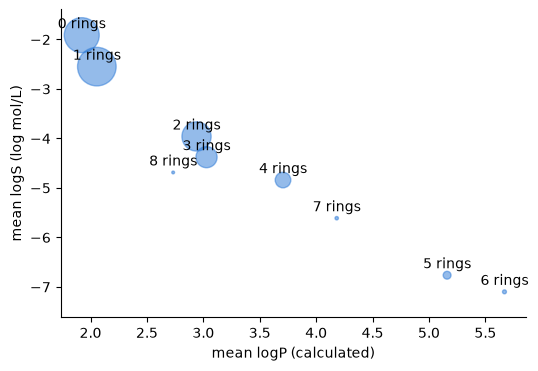

Pearson correlation between group-mean logS and logP: -0.96


In [29]:
# Final exercise, step 3: groupby and plot
group_esol = esol.groupby("n_rings").agg(
    mean_logS=("logS", "mean"),
    mean_logP=("logp", "mean"),
    n=("logS", "count"),
)

display(round(group_esol, 2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(group_esol["mean_logP"], group_esol["mean_logS"], s=group_esol["n"]*2, alpha=0.5, color="#2a78d6")
for n_rings, row in group_esol.iterrows():
    ax.annotate(f"{n_rings} rings", (row["mean_logP"], row["mean_logS"]), textcoords="offset points", xytext=(0, 5), ha="center")
ax.set_xlabel("mean logP (calculated)")
ax.set_ylabel("mean logS (log mol/L)")
ax.margins(y=0.1)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

pearson_logp = group_esol["mean_logS"].corr(group_esol["mean_logP"])

print(f"Pearson correlation between group-mean logS and logP: {pearson_logp:.2f}")

r = -0.96 is the calculated correlation from 9 group averages and not from all compounds. This way, it might seem that there is a strong correlation of ring number and solubility. The problem is that every group counts equally even though the 8-ring group only has 2 compounds whereas the 1-ring group has 386 compounds. 

There seems to be some correlation between ring number and solubility but 7- and 8-rings are more soluble. There is a trend from 2->3 and 4-> 5 but not for 6-8 (tiny groups). The 8-ring group has a low mean logP and a relative high logS, exactly where the logP line predicts. This is still true to "higher logP -> less soluble".

The plot shows that groups with higher mean logP have a lower mean logS across the groups.